In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\subha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_csv("../data/processed/penguins_cleaned.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

Dataset loaded successfully!

First 5 rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen           39.10           18.7              181.0   
1  Adelie  Torgersen           39.50           17.4              186.0   
2  Adelie  Torgersen           40.30           18.0              195.0   
3  Adelie  Torgersen           44.45           17.3              197.0   
4  Adelie  Torgersen           36.70           19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3       4050.0    MALE  
4       3450.0  FEMALE  

Dataset Shape:
(344, 7)


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Missing Values:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     344 non-null    float64
 3   bill_depth_mm      344 non-null    float64
 4   flipper_length_mm  344 non-null    float64
 5   body_mass_g        344 non-null    float64
 6   sex                344 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Species Distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [8]:
X = df[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
        "island"
    ]
]

y = df["species"]

print("Input features selected!")
print("Target variable selected!")

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input features selected!
Target variable selected!

Input Features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     island
0           39.10           18.7              181.0       3750.0  Torgersen
1           39.50           17.4              186.0       3800.0  Torgersen
2           40.30           18.0              195.0       3250.0  Torgersen
3           44.45           17.3              197.0       4050.0  Torgersen
4           36.70           19.3              193.0       3450.0  Torgersen

Target Variable:
0    Adelie
1    Adelie
2    Adelie
3    Adelie
4    Adelie
Name: species, dtype: str


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nData splitting completed successfully!")

Training data: (275, 5)
Testing data: (69, 5)

Data splitting completed successfully!


In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorical_features = ["island"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Baseline Logistic Regression model created successfully!")

Baseline Logistic Regression model created successfully!


In [11]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [12]:
y_pred = model.predict(X_test)

print("Actual Species:")
print(y_test.values[:10])

print("\nPredicted Species:")
print(y_pred[:10])

Actual Species:
<StringArray>
[   'Adelie',    'Adelie',    'Gentoo',    'Gentoo', 'Chinstrap',    'Adelie',
 'Chinstrap',    'Gentoo', 'Chinstrap', 'Chinstrap']
Length: 10, dtype: str

Predicted Species:
['Adelie' 'Adelie' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie' 'Chinstrap'
 'Gentoo' 'Chinstrap' 'Chinstrap']


In [13]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

MODEL EVALUATION RESULTS
------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [14]:
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT")
print("---------------------")

print(classification_report(y_test, y_pred))

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



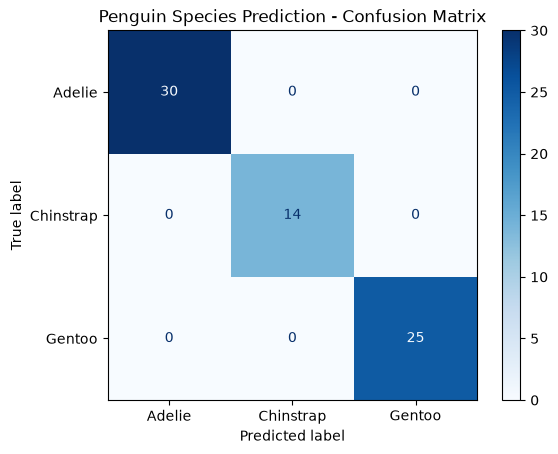

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Penguin Species Prediction - Confusion Matrix")
plt.show()

In [4]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current folder:
c:\Users\subha\Downloads\swynex_task1_data_preparation\swynex_task1_data_preparation\notebooks

Files in current folder:
['task1_data_preparation.ipynb', 'task2_exploratory_data_analysis.ipynb', 'Task_3_Model_Training_Evaluation.ipynb']


In [5]:
import os

for root, dirs, files in os.walk(".."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

..\data\processed\penguins_cleaned.csv


## Limitations of this Model

1. **Small Dataset:** The Palmer Penguins dataset contains only 344 records, which may limit the model's ability to generalize.

2. **Limited Features:** The model uses only four physical measurements and island information. Other factors are not considered.

3. **Simple Algorithm:** Logistic Regression may not capture complex relationships between features.

4. **Data Imputation:** Missing values in the original dataset were replaced with estimated values, which may introduce some bias.

5. **Single Train-Test Split:** The model was evaluated using one train-test split. Its performance may vary with different data splits.

6. **Possible Data Leakage:** If preprocessing statistics were calculated using the entire dataset before splitting, information from the test set may have influenced the training process.

## Conclusion

A baseline Logistic Regression classification model was successfully developed using the Palmer Penguins dataset.

The model achieved 100% accuracy, precision, recall, and F1-score on the 69-record test set.

The confusion matrix confirmed that all test records were classified correctly.

This project demonstrates the application of machine learning for classification and provides a foundation for future improvements using advanced algorithms and cross-validation.